# OliveSmart - import de données sur des oliveraies documentées

Ce notebook contient le code intégral d'import et d'audit. Il complète le notebook
de comparaison existant, sans mélanger l'ancienne zone de culture non confirmée et
les nouvelles parcelles terrain. **Aucun modèle n'est entraîné ici.**

Référence terrain : Ouassanouan et al., *Crop and irrigation type dataset for Moroccan
agricultural regions*, [DOI version 2](https://doi.org/10.6084/m9.figshare.28486022.v2),
licence CC BY 4.0. Le champ `tree=Olives` constitue une observation publiée de culture,
pas un label de stress et pas une confirmation de la culture sur toutes les années.
La version a été publiée le 14 juillet 2025 : sélection rétrospective des sites.

Les capteurs restent ceux du sujet : Sentinel-2 L2A et Landsat Collection 2 L2.
Pour automatiser sans authentification Earth Engine, nous utilisons des miroirs COG
publics des mêmes produits : [Sentinel-2 C1 / Earth Search](https://registry.opendata.aws/sentinel-2-l2a-cogs/)
et Landsat / Planetary Computer. Ce ne sont pas des nouveaux jeux de données fusionnés.
L'accès météo est Open-Meteo avec le modèle explicitement fixé à ERA5-Land. Ce n'est
pas un export du catalogue Earth Engine DAILY_AGGR. Température et humidité du sol
seulement ; la pluie proposée par cette API est forcée par ERA5 et n'est pas substituée.


In [1]:
from pathlib import Path
from IPython.display import display, Image
import json
import pandas as pd
ROOT=Path.cwd()
assert (ROOT/'requirements.txt').exists(), 'Lancer le notebook dans SmartOlive_Sate'
RUN_DOWNLOAD=False  # True pour rechercher et importer ; reprise depuis les caches vérifiés.
RUN_REFERENCE_AUDIT=True
RUN_CONSOLIDATION=True
print('Répertoire :',ROOT.name)


Répertoire : SmartOlive_Sate


## 1. Archives originales et intégrité
Import des polygones et des bandes/NDVI publiés pour 2024 (~68 Mo), comparaison
au MD5 fournisseur, SHA-256 local et contrôle des noms avant extraction. Les photos
de 17 Go ne sont pas téléchargées ni présentées comme inspectées. Les CSV publiés
ne comportent pas de fractions de pixels QA ou de facteurs physiques explicites :
bandes conservées brutes, NDVI fourni conservé sans recalcul d'autres indices.


In [2]:
if RUN_DOWNLOAD:
    """Import reproductible de la référence terrain publiée (culture, pas stress)."""
    from pathlib import Path
    import hashlib
    import json
    import requests
    import subprocess
    import socket
    import urllib3.util.connection
    from requests.adapters import HTTPAdapter
    from urllib3.util.retry import Retry
    from datetime import datetime, timezone
    
    ROOT=Path.cwd()
    RAW=ROOT/'data/raw/morocco_reference'; RAW.mkdir(parents=True,exist_ok=True)
    META=ROOT/'data/metadata'; META.mkdir(parents=True,exist_ok=True)
    URL='https://api.figshare.com/v2/articles/28486022/versions/2'
    urllib3.util.connection.allowed_gai_family=lambda: socket.AF_INET
    session=requests.Session()
    session.mount('https://',HTTPAdapter(max_retries=Retry(total=3,backoff_factor=1,status_forcelist=[429,500,502,503,504])))
    response=session.get(URL,timeout=60); response.raise_for_status(); article=response.json()
    (META/'morocco_reference_figshare_v2.json').write_text(json.dumps(article,indent=2),encoding='utf-8')
    manifest=[]
    for f in sorted(article['files'],key=lambda f:f['size']):
        if f['size']>100_000_000: continue  # Photos 17 Go : pas nécessaires à cet import des polygones.
        target=RAW/('parcels.rar' if f['id']==56267117 else 'sentinel2_2024.rar')
        part=target.with_suffix('.part')
        if not target.exists():
            offset=part.stat().st_size if part.exists() else 0
            download_url=f"https://api.figshare.com/v2/file/download/{f['id']}"
            with session.get(download_url,stream=True,headers={'Range':f'bytes={offset}-'} if offset else {},timeout=(15,90)) as r:
                r.raise_for_status()
                mode='ab' if offset and r.status_code==206 else 'wb'
                with part.open(mode) as stream:
                    for block in r.iter_content(1024*1024): stream.write(block)
            assert part.stat().st_size==f['size'],'Taille incorrecte'
            part.replace(target)
        assert target.stat().st_size==f['size']
        md5=hashlib.md5(target.read_bytes()).hexdigest()
        assert md5==f['computed_md5'],'MD5 fournisseur incorrect'
        print(target.name,target.stat().st_size,'MD5 fournisseur OK',flush=True)
        manifest.append(dict(source=article['doi'],version=2,url=f['download_url'],original_name=f['name'],file=str(target.relative_to(ROOT)),bytes=target.stat().st_size,md5=md5,sha256=hashlib.sha256(target.read_bytes()).hexdigest(),license=article['license'],integrity='Taille et MD5 fournisseur vérifiés',retrieved_utc=datetime.now(timezone.utc).isoformat()))
        listing=subprocess.run(['tar','-tf',str(target)],capture_output=True,text=True,check=True)
        print(listing.stdout[:2500],flush=True)
        # Contrôle des noms avant extraction, aucune traversée hors destination.
        for name in listing.stdout.splitlines():
            dest=(RAW/name).resolve()
            assert dest.is_relative_to(RAW.resolve()),'Chemin archive non sûr'
        subprocess.run(['tar','-xf',str(target),'-C',str(RAW)],check=True)
    (META/'morocco_reference_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
    print('Import référence terminé',flush=True)


## 2. Audit des cultures et sélection du pilote
Inventaire complet des lignes `tree=Olives`. La géométrie invalide est conservée dans
l'inventaire et exclue du pilote. Les cultures intercalaires sont distinguées.
Les doublons identiques sont dédupliqués ; toutes les lignes de dates contradictoires
sans identifiant de scène sont exclues du tableau dérivé et consignées. Aucun original
n'est modifié. Les séries absentes restent absentes.

Pilote : trois parcelles à El Haouz et trois au Tadla, choisies sans voir les résultats
satellites parmi les oliveraies sans culture intercalaire indiquée, valides et d'au moins
un hectare. Leur voisinage facilite les découpes. Le plus grand champ de chaque région
sert d'ancre. Aucun identifiant de ferme ou de bassin n'est fabriqué : ces valeurs restent
nulles. Les régions du fournisseur ne sont pas des bassins hydrologiques.


In [3]:
if RUN_REFERENCE_AUDIT:
    """Audit du terrain publié et sélection d'un petit pilote sans étiquettes inventées."""
    from pathlib import Path
    import json
    import geopandas as gpd
    import pandas as pd
    from shapely.geometry import box
    
    ROOT=Path.cwd()
    RAW=ROOT/'data/raw/morocco_reference'
    META=ROOT/'data/metadata'; OUT=ROOT/'data/processed'; OUT.mkdir(exist_ok=True)
    fields=gpd.read_file(next(RAW.rglob('*.shp')))
    assert fields.crs.to_epsg()==4326
    assert fields.parcel_id.is_unique
    olive=fields[fields.tree.eq('Olives')].copy()
    olive['area_ha']=olive.to_crs(6933).area/10000
    olive['geometry_valid']=olive.geometry.is_valid
    olive['crop_observed_at']=pd.to_datetime(olive.date).dt.strftime('%Y-%m-%d')
    olive['crop_evidence']='terrain publié : tree=Olives ; DOI 10.6084/m9.figshare.28486022.v2'
    olive['stress_label']=None
    olive['farm_id']=None
    olive['basin_id']=None
    olive['source_doi']='10.6084/m9.figshare.28486022.v2'
    olive['source_release_date']='2025-07-14'
    olive['mixed_crop']=~olive.crop.eq('Trees')
    olive['date']=olive.crop_observed_at
    dest=ROOT/'data/raw/maroc/oliveraies_reference.geojson'
    olive.to_file(dest,driver='GeoJSON')
    olive.drop(columns='geometry').to_csv(OUT/'olive_parcels_inventory.csv',index=False)
    files={p.stem.removesuffix('_S2_timeseries'):p for p in RAW.rglob('*_S2_timeseries.csv') if '.ipynb_checkpoints' not in p.parts}
    records=[]; missing=[]; duplicate_audit=[]
    for row in olive.itertuples():
        path=files.get(row.parcel_id)
        if path is None: missing.append(row.parcel_id); continue
        df=pd.read_csv(path)
        assert {'NDVI','date'}<=set(df),str(path)
        df['date']=pd.to_datetime(df.date,errors='raise')
        n_exact=int(df.duplicated().sum())
        df=df.drop_duplicates().copy()
        conflicting=df.date.duplicated(keep=False)
        if n_exact or conflicting.any():
            duplicate_audit.append(dict(parcel_id=row.parcel_id,exact_duplicates_removed=n_exact,
                                        ambiguous_rows_excluded=int(conflicting.sum())))
        # Sans identifiant d'acquisition, ne pas choisir arbitrairement entre deux valeurs.
        df=df.loc[~conflicting].copy()
        df['parcel_id']=row.parcel_id
        df['region']=row.zone
        df['source_file']=str(path.relative_to(ROOT))
        df['qa_coverage_available']=False
        df['stress_label']=None
        records.append(df)
    series=pd.concat(records,ignore_index=True).sort_values(['parcel_id','date'])
    series.to_csv(OUT/'olive_reference_series_2024.csv',index=False)
    pd.DataFrame(duplicate_audit).to_csv(META/'reference_series_duplicate_audit.csv',index=False)
    eligible=olive[olive.geometry_valid & olive.crop.eq('Trees') & olive.area_ha.ge(1)].copy()
    # Deux régions publiées ; choisir les parcelles les plus proches de la plus grande
    # de chaque région. Aucun résultat satellite ne participe à cette sélection.
    pilots=[]
    for region in ['el haouz','Tadla']:
        candidates=eligible[eligible.zone.eq(region)].copy()
        projected=candidates.to_crs(32629)
        anchor=projected.loc[candidates.area_ha.idxmax()].geometry.centroid
        candidates['distance_to_anchor_m']=projected.geometry.centroid.distance(anchor)
        pilots.append(candidates.sort_values(['distance_to_anchor_m','parcel_id']).head(3))
    pilot=gpd.GeoDataFrame(pd.concat(pilots,ignore_index=True),crs=4326)
    pilot.to_file(ROOT/'data/raw/maroc/oliveraies_pilote.geojson',driver='GeoJSON')
    pilot.drop(columns='geometry').to_csv(OUT/'olive_pilot_inventory.csv',index=False)
    summary=dict(source_doi='10.6084/m9.figshare.28486022.v2',license='CC BY 4.0',
                 all_parcels=len(fields),olive_labelled_parcels=len(olive),
                 pure_olive_parcels=int(olive.crop.eq('Trees').sum()),invalid_olive_geometries=int((~olive.geometry_valid).sum()),
                 parcels_with_published_series=int(series.parcel_id.nunique()),series_rows=len(series),
                 first_date=str(series.date.min()),last_date=str(series.date.max()),
                 missing_series=missing,regions=olive.zone.value_counts().to_dict(),
                 exact_duplicate_rows_removed=sum(r['exact_duplicates_removed'] for r in duplicate_audit),
                 ambiguous_rows_excluded=sum(r['ambiguous_rows_excluded'] for r in duplicate_audit),
                 pilot_parcels=pilot.parcel_id.tolist(),
                 caveats=['Culture observée au jour de visite, pas confirmation rétroactive sur toutes les années.',
                          'Aucun label de stress ; aucun identifiant exploitation ou bassin hydrologique fourni.',
                          'Bandes des CSV publiés conservées brutes : facteur/offset et taux de pixels QA non fournis dans les fichiers.',
                          'NDVI fourni par les auteurs conservé sans recalcul ; indices physiques à extraire des rasters audités.',
                          'Les régions source ne sont pas des bassins hydrologiques.',
                          'La géométrie invalide reste dans inventaire et est exclue du pilote sans correction silencieuse.'])
    (META/'morocco_reference_audit.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
    print(json.dumps(summary,indent=2,ensure_ascii=False))
    print(pilot[['parcel_id','zone','area_ha','distance_to_anchor_m']].to_string(index=False))
    print('BBox pilote :',pilot.total_bounds)


{
  "source_doi": "10.6084/m9.figshare.28486022.v2",
  "license": "CC BY 4.0",
  "all_parcels": 10383,
  "olive_labelled_parcels": 868,
  "pure_olive_parcels": 564,
  "invalid_olive_geometries": 1,
  "parcels_with_published_series": 855,
  "series_rows": 29886,
  "first_date": "2024-01-01 00:00:00",
  "last_date": "2024-12-26 00:00:00",
  "missing_series": [
    "Tadla_Trees_20240222_019",
    "Tadla_mixte_20240223_003",
    "Tadla_mixte_20240223_004",
    "Tadla_mixte_20240223_005",
    "Tadla_mixte_20240223_006",
    "Tadla_mixte_20240223_007",
    "Tadla_Trees_20240223_003",
    "Tadla_mixte_20240223_008",
    "Tadla_mixte_20240223_009",
    "Tadla_mixte_20240223_010",
    "Tadla_mixte_20240223_011",
    "Tadla_mixte_20240223_012",
    "Tadla_mixte_20240223_013"
  ],
  "regions": {
    "el haouz": 647,
    "Tadla": 185,
    "Doukkala": 15,
    "Gharb": 9,
    "Souss": 7,
    "Statte": 5
  },
  "exact_duplicate_rows_removed": 1,
  "ambiguous_rows_excluded": 16609,
  "pilot_parcels": 

## 3. Séries satellitaires sur les mêmes polygones
Sentinel-2 C1 2021-2024 : un candidat par fenêtre de 10 jours. Landsat 8/9 Collection 2
2015-2024 : un candidat par mois pour un historique indépendant. Sélection par nuages
de scène avant calcul des indices ; couverture de l'ensemble du groupe vérifiée.
**Échantillonnage, pas composite de toutes les acquisitions.** Les fenêtres sans candidat
ou de mauvaise qualité restent des trous. Une autre scène peut être utile si le meilleur
candidat de scène est localement nuageux : cette reprise locale n'est pas encore implémentée.

Les fenêtres COG sont lues et conservées en NPZ avec grille, SHA-256 et URLs sources
non signées. Les offsets/échelles des assets C1 sont appliqués ; l'ancien miroir S2
aux offsets contradictoires a été exclu. Grille commune à 20 m, moyennes pour bandes
spectrales et plus proche voisin pour QA. SCL 4/5 conservées ; eau et nuages exclus.
Landsat : QA_PIXEL (bits 0-5) et saturation B4/B5/occlusion terrain (QA_RADSAT).
NDVI, NDRE, NDWI vert/NIR et SAVI L=0,5 pour S2 ; NDVI séparé pour Landsat.


In [4]:
"""Import public de découpes Sentinel-2/Landsat sur six parcelles terrain.

Les COG sont des miroirs des produits ESA/USGS, pas de nouveaux capteurs.
Un candidat au maximum par fenêtre de 10 jours (S2) ou mois (Landsat), choisi
sur nuages de scène ; les trous et rejets locaux restent explicites.
"""
from pathlib import Path
import argparse
import concurrent.futures
import hashlib
import json
import math
import time
import threading
from urllib.parse import urlparse
from datetime import datetime, timezone
import geopandas as gpd
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from shapely.geometry import shape

ROOT=Path.cwd()
RAW=ROOT/'data/raw/pilot'; META=ROOT/'data/metadata/pilot'; OUT=ROOT/'data/processed/pilot'
for p in [RAW,META,OUT]:p.mkdir(parents=True,exist_ok=True)
PILOT=gpd.read_file(ROOT/'data/raw/maroc/oliveraies_pilote.geojson')
CONFIG={'processing_version':2,'sentinel_start':'2021-01-01','landsat_start':'2015-01-01','end':'2024-12-31',
        'step_days':10,'max_scene_cloud':40,'min_valid_fraction':.6,
        'selection':'minimum eo:cloud_cover parmi les scènes couvrant le groupe, par fenêtre, sans accès aux résultats',
        'qa_sentinel_classes':[4,5], 'note':'eau exclue du pilote oléicole ; échantillonnage temporel, pas composite de toutes les scènes'}
SAS_CACHE={}
SAS_LOCK=threading.Lock()
from types import SimpleNamespace
args=SimpleNamespace(smoke=False, source="all", workers=4)
def session():
    s=requests.Session(); s.mount('https://',HTTPAdapter(max_retries=Retry(total=2,backoff_factor=1,status_forcelist=[429,500,502,503,504])))
    return s

def search(region,group,source):
    start='2024-06-01' if args.smoke else CONFIG['sentinel_start' if source=='sentinel2' else 'landsat_start']
    end='2024-06-30' if args.smoke else CONFIG['end']
    col='sentinel-2-c1-l2a' if source=='sentinel2' else 'landsat-c2-l2'
    api='https://earth-search.aws.element84.com/v1/search' if source=='sentinel2' else 'https://planetarycomputer.microsoft.com/api/stac/v1/search'
    slug=region.replace(' ','_')
    dest=META/f'{col}_{slug}_{start}_{end}_catalogue.json'
    if dest.exists(): items=json.loads(dest.read_text())['features']
    else:
        items=[]; client=session()
        for year in range(int(start[:4]),int(end[:4])+1):
            begin=max(start,f'{year}-01-01');finish=min(end,f'{year}-12-31')
            yearfile=META/f'{col}_{slug}_{begin}_{finish}_part.json'
            if yearfile.exists():items.extend(json.loads(yearfile.read_text())['features']);continue
            yearitems=[];url=api
            params={'collections':col,'bbox':','.join(map(str,group.total_bounds)),
                    'datetime':begin+'T00:00:00Z/'+finish+'T23:59:59Z','limit':100}
            while url:
                r=client.get(url,params=params,timeout=(20,90));r.raise_for_status();data=r.json()
                yearitems.extend(data['features'])
                link=next((l for l in data.get('links',[]) if l['rel']=='next'),None)
                url=link['href'] if link else None;params=None
            yearfile.write_text(json.dumps({'type':'FeatureCollection','features':yearitems}))
            items.extend(yearitems)
        dest.write_text(json.dumps({'type':'FeatureCollection','features':items},indent=2))
    union=group.geometry.union_all()
    candidates={}
    for item in items:
        props=item['properties']; cloud=props.get('eo:cloud_cover',100)
        if cloud is None or cloud>CONFIG['max_scene_cloud']:continue
        if not shape(item['geometry']).covers(union):continue
        if source=='landsat' and props.get('platform') not in ['landsat-8','landsat-9']:continue
        dt=pd.Timestamp(props['datetime'])
        # Origine annuelle fixe, la dernière fenêtre de l'année peut être courte.
        key=(dt.year,(dt.dayofyear-1)//10) if source=='sentinel2' else (dt.year,dt.month)
        rank=(cloud,props['datetime'],item['id'])
        if key not in candidates or rank<candidates[key][0]:candidates[key]=(rank,item)
    selected=[v[1] for _,v in sorted(candidates.items())]
    if args.smoke:selected=selected[:1]
    print(source,region,':',len(items),'catalogue,',len(selected),'candidats retenus',flush=True)
    return selected

def raster_crop(item,key,source,grid,client):
    asset=item['assets'][key]; url=asset['href']
    if source=='landsat':
        parsed=urlparse(url)
        account=parsed.hostname.split('.')[0];container=parsed.path.split('/')[1]
        cache_key=(account,container)
        with SAS_LOCK:
            if cache_key not in SAS_CACHE:
                sign=client.get(f'https://planetarycomputer.microsoft.com/api/sas/v1/token/{account}/{container}',timeout=30)
                sign.raise_for_status();SAS_CACHE[cache_key]=sign.json()['token']
            token=SAS_CACHE[cache_key]
        url=url+'?'+token
    qa=key in ['scl','qa_pixel','qa_radsat']
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR',CPL_VSIL_CURL_ALLOWED_EXTENSIONS='.tif,.TIF',
                      GDAL_HTTP_CONNECTTIMEOUT=20,GDAL_HTTP_TIMEOUT=60,GDAL_HTTP_MAX_RETRY=2,GDAL_HTTP_RETRY_DELAY=1,
                      GDAL_HTTP_IPRESOLVE='V4',VSI_CACHE=True):
        with rasterio.open(url) as src:
            with WarpedVRT(src,crs='EPSG:32629',transform=grid['transform'],width=grid['width'],height=grid['height'],
                           src_nodata=src.nodata,nodata=0,resampling=Resampling.nearest if qa else Resampling.average,
                           dtype='uint16' if qa else 'float32') as warped:
                array=warped.read(1)
    metadata=asset.get('raster:bands',[{}])[0]
    if not qa:
        if 'scale' not in metadata:raise ValueError('Facteur physique manquant dans STAC : '+item['id']+' '+key)
        valid=array!=metadata.get('nodata',0)
        array=array*metadata['scale']+metadata.get('offset',0)
        array[~valid]=np.nan
    return array

def process(region,group,source,item):
    slug=region.replace(' ','_'); folder=RAW/source/slug;folder.mkdir(parents=True,exist_ok=True)
    dest=folder/(item['id']+'.npz'); stats=folder/(item['id']+'.json')
    if dest.exists() and stats.exists():
        prior=json.loads(stats.read_text())
        if prior.get('config',{}).get('processing_version')==CONFIG['processing_version'] and hashlib.sha256(dest.read_bytes()).hexdigest()==prior['sha256']:return prior['rows']
    projected=group.to_crs(32629)
    resolution=20 if source=='sentinel2' else 30
    xmin,ymin,xmax,ymax=projected.total_bounds
    xmin=math.floor(xmin/resolution)*resolution;ymax=math.ceil(ymax/resolution)*resolution
    grid=dict(transform=from_origin(xmin,ymax,resolution,resolution),width=math.ceil((xmax-xmin)/resolution),height=math.ceil((ymax-ymin)/resolution))
    client=session()
    keys=['scl','green','red','rededge1','nir','nir08'] if source=='sentinel2' else ['qa_pixel','qa_radsat','red','nir08']
    arrays={key:raster_crop(item,key,source,grid,client) for key in keys}
    if source=='sentinel2':valid=np.isin(arrays['scl'],CONFIG['qa_sentinel_classes'])
    else:
        valid=(arrays['qa_pixel'] & 63)==0
        # L8/L9 : saturation des seules bandes utilisées B4/B5 + occlusion terrain.
        valid &= (arrays['qa_radsat'] & ((1<<3)|(1<<4)|(1<<11)))==0
    for key in keys:
        if key not in ['scl','qa_pixel','qa_radsat']:valid &= np.isfinite(arrays[key])
    def ratio(a,b):
        den=a+b
        return np.divide(a-b,den,out=np.full_like(den,np.nan),where=np.abs(den)>1e-6)
    nir=arrays['nir'] if source=='sentinel2' else arrays['nir08'];red=arrays['red']
    indices={'ndvi':ratio(nir,red)}
    if source=='sentinel2':
        indices['ndre']=ratio(arrays['nir08'],arrays['rededge1'])
        indices['ndwi']=ratio(arrays['green'],nir)
        den=nir+red+.5
        indices['savi']=np.divide(1.5*(nir-red),den,out=np.full_like(den,np.nan),where=np.abs(den)>1e-6)
    for values in indices.values():valid &= np.isfinite(values)
    rows=[]
    for row in projected.itertuples():
        inside=geometry_mask([row.geometry.__geo_interface__],out_shape=valid.shape,transform=grid['transform'],invert=True)
        good=inside & valid;n=int(inside.sum());ng=int(good.sum())
        fraction=ng/n if n else 0
        result=dict(parcel_id=row.parcel_id,region=region,date=item['properties']['datetime'],source=source,
                    item_id=item['id'],scene_cloud_percent=item['properties'].get('eo:cloud_cover'),
                    n_pixels=n,n_valid_pixels=ng,valid_fraction=fraction,accepted=fraction>=CONFIG['min_valid_fraction'],
                    crop_observed_at=str(row.crop_observed_at)[:10],source_release_date='2025-07-14',stress_label=None)
        for name,array in indices.items():
            result[name]=float(np.mean(array[good])) if ng else None
        rows.append(result)
    temp=dest.with_suffix('.part.npz')
    np.savez_compressed(temp,**arrays,valid_mask=valid,transform=np.array(tuple(grid['transform'])),crs='EPSG:32629')
    temp.replace(dest)
    metadata={'item_id':item['id'],'source':source,'date':item['properties']['datetime'],
              'unsigned_assets':{k:item['assets'][k] for k in keys},'config':CONFIG,
              'file':str(dest.relative_to(ROOT)),'sha256':hashlib.sha256(dest.read_bytes()).hexdigest(),
              'grid':{'crs':'EPSG:32629','transform':list(grid['transform']),'width':grid['width'],'height':grid['height']},
              'scale_policy':'raster:bands scale et offset appliqués ; aucun offset supplémentaire fondé sur le nom',
              'rows':rows,'retrieved_utc':datetime.now(timezone.utc).isoformat()}
    stats.write_text(json.dumps(metadata,indent=2,ensure_ascii=False))
    print(source,region,item['id'],'OK',flush=True)
    return rows

def main():
    (META/'import_config.json').write_text(json.dumps(CONFIG,indent=2))
    tasks=[]
    for region,group in PILOT.groupby('zone'):
        for source in (['sentinel2','landsat'] if args.source=='all' else [args.source]):
            for item in search(region,group,source):tasks.append((region,group,source,item))
    errors=[];rows=[]
    with concurrent.futures.ThreadPoolExecutor(max_workers=args.workers) as pool:
        futures={pool.submit(process,*task):task for task in tasks}
        for future in concurrent.futures.as_completed(futures):
            task=futures[future]
            try:rows.extend(future.result())
            except Exception as exc:
                if isinstance(exc,TypeError):
                    import traceback
                    traceback.print_exc(limit=8)
                # Ne pas stocker de lien SAS dans le diagnostic.
                error=dict(source=task[2],region=task[0],item_id=task[3]['id'],error_type=type(exc).__name__)
                errors.append(error);print('ERREUR',error,flush=True)
    suffix='_smoke' if args.smoke else ''
    pd.DataFrame(rows).to_csv(OUT/f'satellite_acquisitions{suffix}_{args.source}.csv',index=False)
    (META/f'import_errors{suffix}_{args.source}.json').write_text(json.dumps(errors,indent=2))
    print('Terminé :',len(rows),'observations parcelle-date ;',len(errors),'erreurs',flush=True)
    if errors:raise SystemExit(2)
if RUN_DOWNLOAD:
    main()


## 4. Météo ERA5-Land, point de grille régional
Les deux points sont les centroïdes des ensembles de parcelles projetés en UTM,
reconvertis en WGS84. Les coordonnées du point de grille effectivement retourné sont
conservées. Modèle `era5_land`, UTC, altitude non corrigée, maille la plus proche.
Variables : température moyenne (°C) et humidité volumique du sol 0-7 cm (m³/m³),
du 1er janvier 2021 au 31 décembre 2024. Pas de mesure locale d'irrigation.
[Documentation des modèles et variables](https://open-meteo.com/en/docs/historical-weather-api).


In [5]:
if RUN_DOWNLOAD:
    """ERA5-Land via Open-Meteo, modèle explicitement fixé, sans mélange de pluie ERA5."""
    from pathlib import Path
    import json
    import hashlib
    from datetime import datetime,timezone
    import requests
    import geopandas as gpd
    import pandas as pd
    
    ROOT=Path.cwd()
    RAW=ROOT/'data/raw/pilot/era5_land_openmeteo';RAW.mkdir(parents=True,exist_ok=True)
    META=ROOT/'data/metadata/pilot';META.mkdir(parents=True,exist_ok=True)
    OUT=ROOT/'data/processed/pilot';OUT.mkdir(parents=True,exist_ok=True)
    pilot=gpd.read_file(ROOT/'data/raw/maroc/oliveraies_pilote.geojson')
    records=[];manifest=[]
    for region,group in pilot.groupby('zone'):
        center=group.to_crs(32629).geometry.union_all().centroid
        point=gpd.GeoSeries([center],crs=32629).to_crs(4326).iloc[0]
        path=RAW/(region.replace(' ','_')+'_2021_2024.json')
        params=dict(latitude=point.y,longitude=point.x,start_date='2021-01-01',end_date='2024-12-31',
                    models='era5_land',daily='temperature_2m_mean,soil_moisture_0_to_7cm_mean',
                    timezone='UTC',elevation='nan',cell_selection='nearest')
        if path.exists():data=json.loads(path.read_text())
        else:
            response=requests.get('https://archive-api.open-meteo.com/v1/archive',params=params,timeout=(20,120))
            if response.status_code!=200:raise ValueError(response.text[:300])
            data=response.json();path.write_text(json.dumps(data,indent=2))
        assert data['daily_units']['temperature_2m_mean']=='°C'
        assert data['daily_units']['soil_moisture_0_to_7cm_mean']=='m³/m³'
        frame=pd.DataFrame(data['daily']).rename(columns={'time':'date','temperature_2m_mean':'temperature_c','soil_moisture_0_to_7cm_mean':'soil_moisture_m3m3'})
        frame['date']=pd.to_datetime(frame.date)
        assert len(frame)==1461 and frame.date.is_unique
        assert frame.temperature_c.notna().all() and frame.soil_moisture_m3m3.notna().all()
        frame['weather_region']=region;frame['model']='ERA5-Land';frame['access_provider']='Open-Meteo'
        frame['grid_latitude']=data['latitude'];frame['grid_longitude']=data['longitude']
        records.append(frame)
        manifest.append(dict(file=str(path.relative_to(ROOT)),bytes=path.stat().st_size,
                             sha256=hashlib.sha256(path.read_bytes()).hexdigest(),published_checksum=None,
                             source='Copernicus ERA5-Land, accès et agrégations Open-Meteo',
                             url='https://archive-api.open-meteo.com/v1/archive',request=params,
                             response_units=data['daily_units'],response_grid={'latitude':data['latitude'],'longitude':data['longitude']},
                             integrity='JSON, unités, calendrier complet et valeurs non nulles vérifiés',
                             retrieved_utc=datetime.now(timezone.utc).isoformat(),
                             caveat='Point de grille régional, non une station dans la parcelle. Pas le produit Earth Engine DAILY_AGGR ; pas de pluie ERA5 ajoutée silencieusement.'))
        print(region,len(frame),'jours ERA5-Land importés',flush=True)
    pd.concat(records,ignore_index=True).to_csv(OUT/'era5_land_daily_2021_2024.csv',index=False)
    (META/'weather_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')


## 5. Consolidation, contrôles et résultats
Seules les découpes de version de traitement valide et SHA-256 vérifié entrent dans
le tableau final. Les autres essais restent dans les fichiers bruts mais sont exclus.
La date de chaque fenêtre est sa fin exclusive ; l'acquisition et les jours météo
précèdent cette date. Pas d'interpolation, pas de remplissage depuis le futur.
La météo n'est agrégée que si tous les jours sont disponibles. Les valeurs d'indices
ne sont exposées à l'apprentissage que si fraction QA ≥0,6 et plages admissibles.
Les observations rejetées sont conservées dans le journal d'acquisitions.


In [6]:
if RUN_CONSOLIDATION:
    """Consolide uniquement les découpes vérifiées, conserve les trous et la provenance."""
    from pathlib import Path
    import hashlib
    import json
    from datetime import timedelta
    import geopandas as gpd
    import pandas as pd
    import numpy as np
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    
    ROOT=Path.cwd()
    RAW=ROOT/'data/raw/pilot'; META=ROOT/'data/metadata/pilot';OUT=ROOT/'data/processed/pilot'
    REPORT=ROOT/'outputs/pilot';REPORT.mkdir(parents=True,exist_ok=True)
    pilot=gpd.read_file(ROOT/'data/raw/maroc/oliveraies_pilote.geojson')
    rows=[];manifest=[]
    full_run=OUT/'satellite_acquisitions_all.csv'
    assert full_run.exists(),'Attendre la fin du téléchargement complet avant consolidation'
    selected=pd.read_csv(full_run)
    selected_ids=set(zip(selected.source,selected.item_id))
    for source in ['sentinel2','landsat']:
        for path in (RAW/source).rglob('*.json'):
            data=json.loads(path.read_text())
            if data.get('config',{}).get('processing_version')!=2:continue
            if (source,data['item_id']) not in selected_ids:continue
            # Exclure tous les essais de l'ancien miroir aux offsets contradictoires.
            if source=='sentinel2' and not data['item_id'].startswith(('S2A_T','S2B_T','S2C_T')):continue
            target=ROOT/data['file']
            assert hashlib.sha256(target.read_bytes()).hexdigest()==data['sha256']
            rows.extend(data['rows'])
            manifest.append({k:data[k] for k in ['source','item_id','date','file','sha256','retrieved_utc']})
    frame=pd.DataFrame(rows)
    assert len(frame),'Aucune découpe vérifiée'
    frame['date']=pd.to_datetime(frame.date,utc=True)
    assert not frame.duplicated(['parcel_id','source','date']).any()
    frame=frame.sort_values(['source','parcel_id','date'])
    frame.to_csv(OUT/'satellite_acquisitions_verified.csv',index=False)
    weather=pd.read_csv(OUT/'era5_land_daily_2021_2024.csv',parse_dates=['date'])
    weather['date']=pd.to_datetime(weather.date,utc=True)
    calendar=[]
    for parcel in pilot.itertuples():
        part=frame[frame.parcel_id.eq(parcel.parcel_id)&frame.source.eq('sentinel2')]
        meteo=weather[weather.weather_region.eq(parcel.zone)]
        for year in range(2021,2025):
            begin=pd.Timestamp(f'{year}-01-01',tz='UTC');finish=pd.Timestamp(f'{year+1}-01-01',tz='UTC')
            for start in pd.date_range(begin,finish,freq='10D',inclusive='left'):
                end=min(pd.Timestamp(start.to_pydatetime()+timedelta(days=10)),finish)
                candidates=part[part.date.ge(start)&part.date.lt(end)]
                assert len(candidates)<=1,'Plusieurs scènes retenues dans une même fenêtre'
                row=dict(parcel_id=parcel.parcel_id,region=parcel.zone,window_start=start,date=end,
                         acquisition_date=None,accepted=False,qa_valid_fraction=np.nan,
                         status='acquisition_absente',crop_observed_at=str(parcel.crop_observed_at)[:10],
                         crop_evidence_release='2025-07-14',stress_label=np.nan,
                         farm_id=None,basin_id=None)
                for index in ['ndvi','ndre','ndwi','savi']:row[index]=np.nan
                if len(candidates):
                    item=candidates.iloc[0]
                    range_ok=all(pd.notna(item[k]) and -1<=item[k]<=1 for k in ['ndvi','ndre','ndwi'])
                    accepted=bool(item.accepted and range_ok)
                    row.update(acquisition_date=item.date,item_id=item.item_id,qa_valid_fraction=float(item.valid_fraction),
                               accepted=accepted,status='valide' if accepted else 'rejet_qualite_ou_plage')
                    if accepted:
                        for index in ['ndvi','ndre','ndwi','savi']:row[index]=item[index]
                m=meteo[meteo.date.ge(start)&meteo.date.lt(end)]
                complete=len(m)==(end-start).days and m[['temperature_c','soil_moisture_m3m3']].notna().all().all()
                row['n_weather_days']=len(m)
                row['temperature_c']=float(m.temperature_c.mean()) if complete else np.nan
                row['soil_moisture_m3m3']=float(m.soil_moisture_m3m3.mean()) if complete else np.nan
                row['weather_model']='ERA5-Land via Open-Meteo ; point de grille régional'
                calendar.append(row)
    series=pd.DataFrame(calendar).sort_values(['parcel_id','date'])
    assert not series.duplicated(['parcel_id','date']).any()
    assert series.loc[series.acquisition_date.notna(),'acquisition_date'].lt(series.loc[series.acquisition_date.notna(),'date']).all()
    series.to_csv(OUT/'sentinel2_10day_with_weather.csv',index=False)
    # Landsat historique indépendant, aucune fusion radiométrique avec Sentinel.
    landsat=frame[frame.source.eq('landsat')].copy()
    landsat.to_csv(OUT/'landsat_history.csv',index=False)
    summary=frame.groupby(['source','region']).agg(observations=('parcel_id','size'),
        first=('date','min'),last=('date','max'),accepted=('accepted','sum')).reset_index()
    summary.to_csv(REPORT/'coverage.csv',index=False)
    manifest.extend(json.loads((META/'weather_manifest.json').read_text(encoding='utf-8')))
    (META/'verified_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
    fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
    for ax,(region,group) in zip(axes,pilot.groupby('zone')):
        for parcel in group.parcel_id:
            values=series[series.parcel_id.eq(parcel)]
            ax.plot(values.date,values.ndvi,marker='.',markersize=2,linewidth=.7,label=parcel)
        ax.set_title(region+' - NDVI Sentinel-2, trous conservés');ax.set_ylim(-.2,1);ax.set_ylabel('NDVI');ax.legend(fontsize=6)
    fig.tight_layout();fig.savefig(REPORT/'ndvi_series.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(11,5))
    for ax,(region,group) in zip(axes,pilot.groupby('zone')):
        group.plot(ax=ax,facecolor='#91ae70',edgecolor='#35552e')
        for parcel in group.itertuples():
            point=parcel.geometry.representative_point()
            ax.annotate(parcel.parcel_id.rsplit('_',1)[-1],(point.x,point.y),fontsize=8)
        ax.set_title(region+' - polygones terrain publiés');ax.set_xlabel('Longitude');ax.set_ylabel('Latitude')
    fig.tight_layout();fig.savefig(REPORT/'pilot_map.png',dpi=160);plt.close(fig)
    status=dict(confirmed_crop_source='Terrain publié : DOI 10.6084/m9.figshare.28486022.v2 ; culture au jour de visite',
                pilot_parcels=len(pilot),source_counts=frame.source.value_counts().to_dict(),
                calendar_rows=len(series),accepted_sentinel_rows=int(series.accepted.sum()),
                weather_days=int(len(weather)),trained_models=0,
                pending=['Événements de stress et surveillance exhaustive non disponibles publiquement dans cette référence.',
                         'Identifiants exploitation et bassin hydrologique absents ; régions distinctes ne prouvent pas l’indépendance par exploitation.',
                         'Stabilité de la culture sur les années antérieures aux visites non confirmée.',
                         'Découpes sélectionnées par fenêtre ; pas un composite de toutes les acquisitions.',
                         'Météo via accès Open-Meteo, pas un export du catalogue Earth Engine demandé. Pluie ERA5-Land non importée.'])
    (REPORT/'import_status.json').write_text(json.dumps(status,indent=2,ensure_ascii=False),encoding='utf-8')
    print(summary.to_string(index=False));print(json.dumps(status,indent=2,ensure_ascii=False))


   source   region  observations                            first                             last  accepted
  landsat    Tadla           360 2015-01-03 11:03:47.313810+00:00 2024-12-06 10:57:40.820456+00:00       352
  landsat el haouz           348 2015-01-03 11:04:11.200611+00:00 2024-12-13 11:04:08.521865+00:00       328
sentinel2    Tadla           324 2021-01-01 11:22:07.956000+00:00 2024-12-26 11:22:09.488000+00:00       310
sentinel2 el haouz           327 2021-01-01 11:22:43.990000+00:00 2024-12-31 11:22:29.654000+00:00       303
{
  "confirmed_crop_source": "Terrain publié : DOI 10.6084/m9.figshare.28486022.v2 ; culture au jour de visite",
  "pilot_parcels": 6,
  "source_counts": {
    "landsat": 708,
    "sentinel2": 651
  },
  "calendar_rows": 888,
  "accepted_sentinel_rows": 613,
  "weather_days": 2922,
  "trained_models": 0,
  "pending": [
    "Événements de stress et surveillance exhaustive non disponibles publiquement dans cette référence.",
    "Identifiants exploitati

{'confirmed_crop_source': 'Terrain publié : DOI 10.6084/m9.figshare.28486022.v2 ; culture au jour de visite',
 'pilot_parcels': 6,
 'source_counts': {'landsat': 708, 'sentinel2': 651},
 'calendar_rows': 888,
 'accepted_sentinel_rows': 613,
 'weather_days': 2922,
 'trained_models': 0,
 'pending': ['Événements de stress et surveillance exhaustive non disponibles publiquement dans cette référence.',
  'Identifiants exploitation et bassin hydrologique absents ; régions distinctes ne prouvent pas l’indépendance par exploitation.',
  'Stabilité de la culture sur les années antérieures aux visites non confirmée.',
  'Découpes sélectionnées par fenêtre ; pas un composite de toutes les acquisitions.',
  'Météo via accès Open-Meteo, pas un export du catalogue Earth Engine demandé. Pluie ERA5-Land non importée.']}

,source,region,observations,first,last,accepted
0,landsat,Tadla,360,2015-01-03 11:03:47.313810+00:00,2024-12-06 10:57:40.820456+00:00,352
1,landsat,el haouz,348,2015-01-03 11:04:11.200611+00:00,2024-12-13 11:04:08.521865+00:00,328
2,sentinel2,Tadla,324,2021-01-01 11:22:07.956000+00:00,2024-12-26 11:22:09.488000+00:00,310
3,sentinel2,el haouz,327,2021-01-01 11:22:43.990000+00:00,2024-12-31 11:22:29.654000+00:00,303


,region,status,observations
0,Tadla,acquisition_absente,120
1,Tadla,rejet_qualite_ou_plage,14
2,Tadla,valide,310
3,el haouz,acquisition_absente,117
4,el haouz,rejet_qualite_ou_plage,24
5,el haouz,valide,303


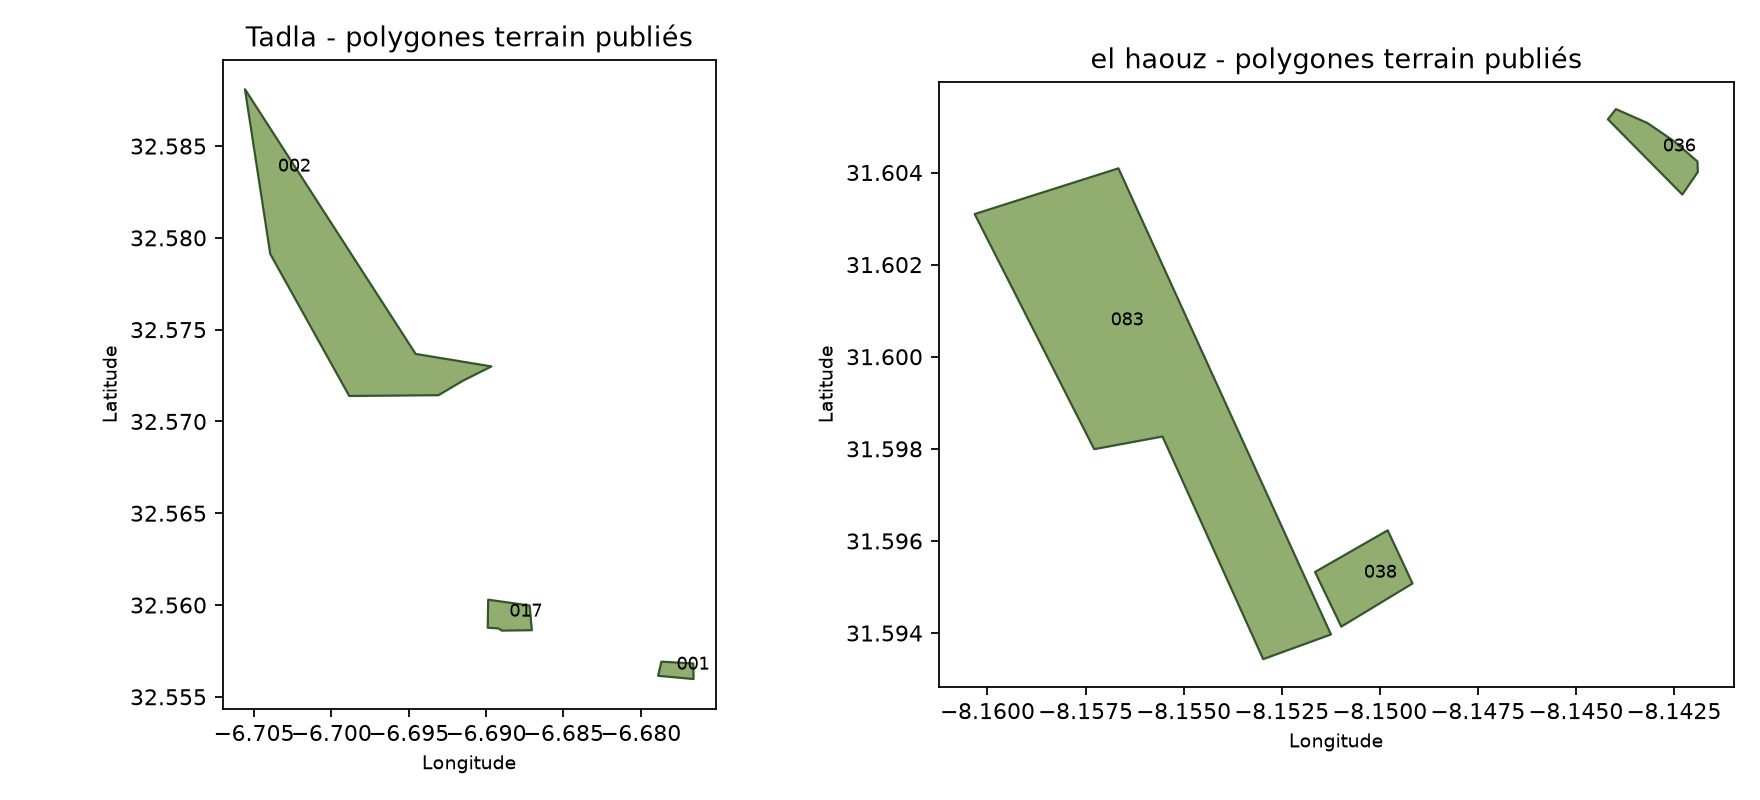

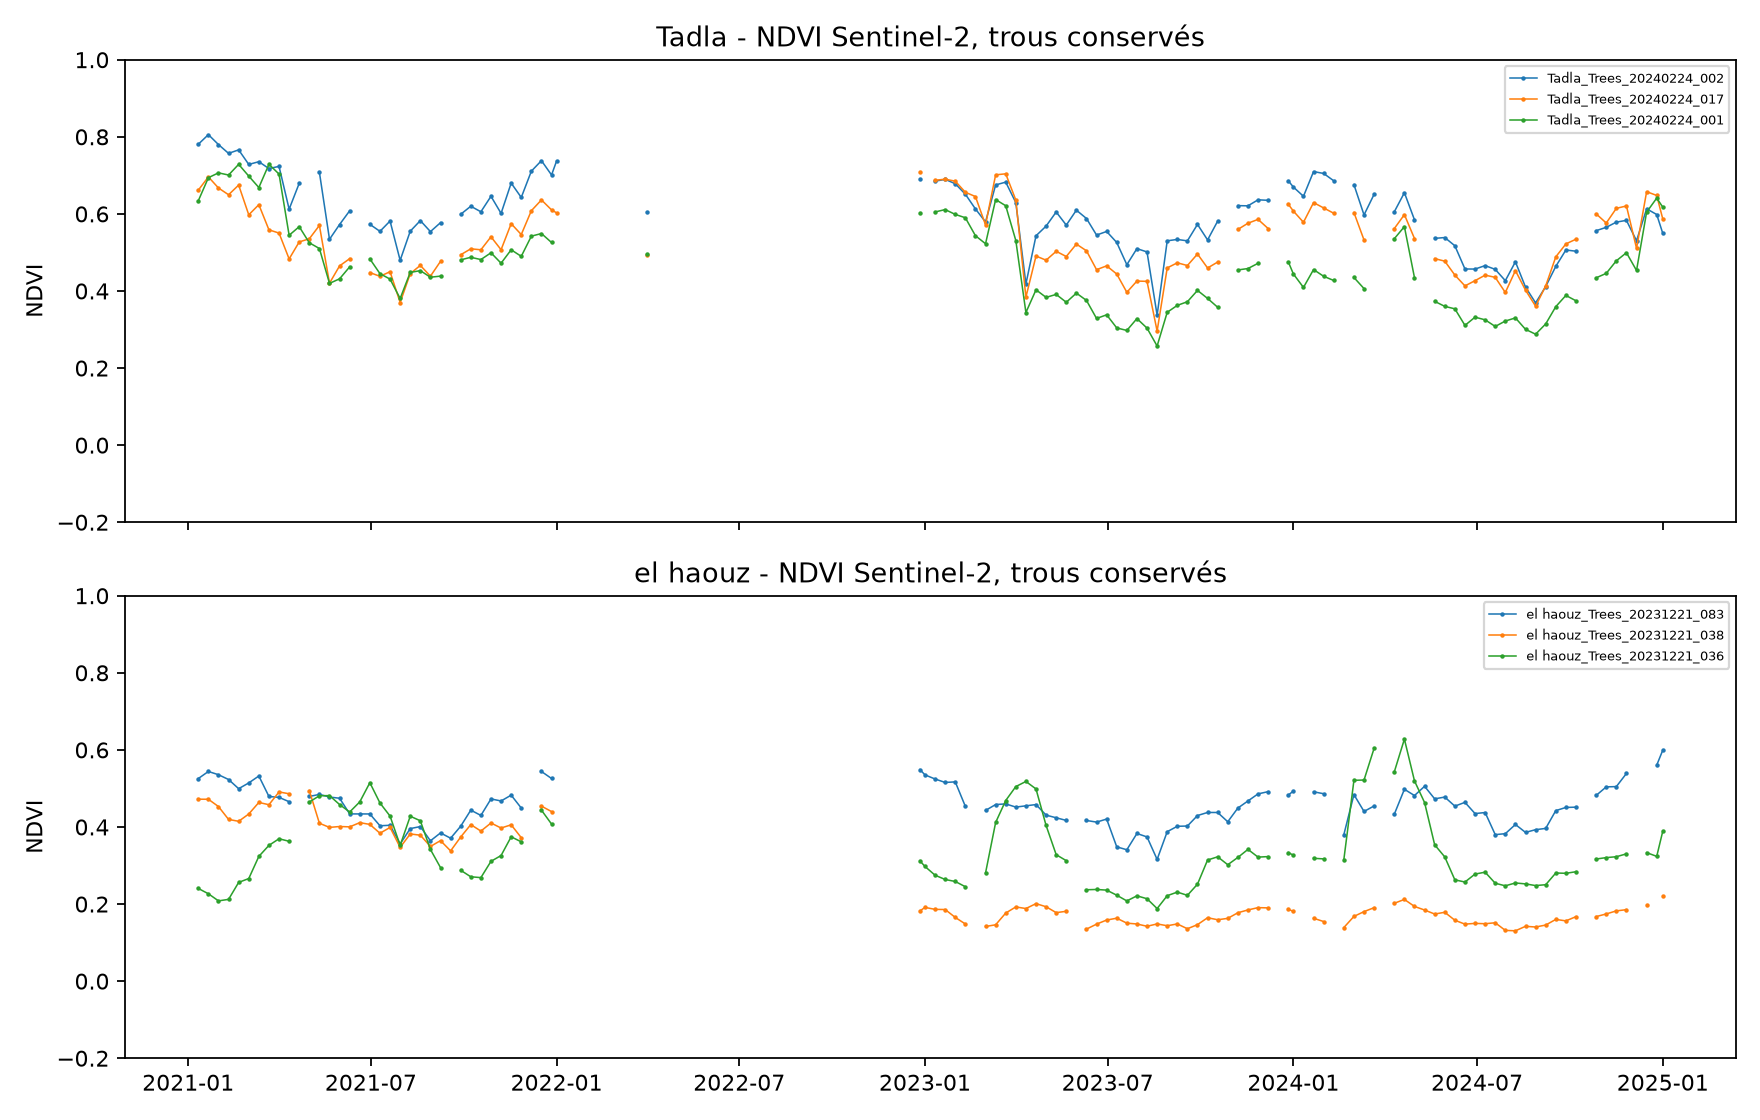

In [7]:
status=json.loads((ROOT/'outputs/pilot/import_status.json').read_text(encoding='utf-8'))
display(status)
display(pd.read_csv(ROOT/'outputs/pilot/coverage.csv'))
series=pd.read_csv(ROOT/'data/processed/pilot/sentinel2_10day_with_weather.csv')
display(series.groupby(['region','status']).size().rename('observations').reset_index())
display(Image(filename=str(ROOT/'outputs/pilot/pilot_map.png')))
display(Image(filename=str(ROOT/'outputs/pilot/ndvi_series.png')))


## Limites avant entraînement et évaluation
- La présence d'oliviers est documentée aux dates de visite ; l'historique de culture
  2021-2024 n'est pas entièrement confirmé. Il faut vérifier les changements de plantation.
- Les séries publiques 2024 et les découpes calculées ont des méthodes différentes :
  ne pas les empiler comme des observations indépendantes d'une même parcelle-date.
- Les six parcelles forment un **petit pilote**, pas une population représentative.
- Aucun événement de stress confirmé ni calendrier de surveillance exhaustive n'est
  fourni. Précision, rappel, F1, délai et faux positifs agronomiques restent non évaluables.
- Les identifiants d'exploitation et de bassin manquent. Une séparation par région
  peut être une expérience spatiale explicitement nommée, pas une preuve d'indépendance
  par exploitation ou de robustesse entre bassins.
- Un protocole d'apprentissage doit être fixé avant tout choix sur test. Ces imports
  ne déclenchent pas automatiquement le notebook historique de comparaison.
